In [44]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np


In [45]:
# Cargando archivo desde Github
url_data = "https://raw.githubusercontent.com/victormaciase/EconometriaFinanciera_MagisterFinanzasWK/refs/heads/main/TrabajoPractico3/bankruptcy.csv"
df = pd.read_csv(url_data, index_col=None, decimal='.')

## **Pregunta 1**

¿Cuántas observaciones hay en el dataset? ¿Qué porcentaje de empresas quebraron dentro de la muestra?

In [46]:
display (df.head())

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [47]:
# 1. Total de observaciones en el dataset
total_observaciones = df.shape[0]
print(f"Total de observaciones: {total_observaciones}")

# 2. Porcentaje de empresas que quebraron
Cantidad_empresas_quiebra = (df['Bankrupt?'] == 1).sum()
print(f"Cantidad de empresas en quiebra: {Cantidad_empresas_quiebra}")
Cantidad_empresas_no_quiebra = (df['Bankrupt?'] == 0).sum()
print(f"Cantidad de empresas no en quiebra: {Cantidad_empresas_no_quiebra}")
porcentaje_quiebra = df['Bankrupt?'].mean() * 100
print(f"Porcentaje de empresas en quiebra: {porcentaje_quiebra:.2f}%")

Total de observaciones: 6819
Cantidad de empresas en quiebra: 220
Cantidad de empresas no en quiebra: 6599
Porcentaje de empresas en quiebra: 3.23%


## **Pregunta 2**

Construye un dataset que incluya sólo a las siguientes variables, renombrándolas de acuerdo a:


    `Bankrupt?` -> `bankruptcy`
    `ROA(C) before interest and depreciation before interest` -> `roa`
    `Debt ratio %` -> `debt_ratio`
    `Total Asset Turnover` -> `asset_turnover`

¿Qué información de los Estados Financieros se requiere para construir los 3 últimos ratios?

In [48]:
df.columns = df.columns.str.strip()
col_bankrupt = [c for c in df.columns if 'Bankrupt' in c][0]
col_roa = [c for c in df.columns if 'ROA(C)' in c][0]
col_debt = [c for c in df.columns if 'Debt ratio' in c][0]
col_turnover = [c for c in df.columns if 'Turnover' in c or 'turnover' in c][0]

columnas_renombrar = {
    col_bankrupt: 'bankruptcy',
    col_roa: 'roa',
    col_debt: 'debt_ratio',
    col_turnover: 'asset_turnover'}

df_2 = df[list(columnas_renombrar.keys())].rename(columns=columnas_renombrar)

# Verificar el resultado
display (df_2.head())

,bankruptcy,roa,debt_ratio,asset_turnover
0,1,0.370594,0.207576,0.086957
1,1,0.464291,0.171176,0.064468
2,1,0.426071,0.207516,0.014993
3,1,0.399844,0.151465,0.089955
4,1,0.465022,0.106509,0.175412


R:

* $$ROA = EBITDA/Activos$$

* $$Deb Ratio = Pasivo/Activo$$

* $$Asset \ Trunover = Ventas Netas/Activos$$

## **Pregunta 3**

**Nota: En las preguntas 3 y siguientes trabajarás sólo con las 4 variables determinadas en la Pregunta 2.**

Presenta una tabla con estadística descriptiva de cada variable que incluya a los valores mínimo y máximo, media aritmética, desviación estándar y percentiles 25, 50 y 75.

In [49]:
df_2.describe()


,bankruptcy,roa,debt_ratio,asset_turnover
count,6819.000000,6819.000000,6819.000000,6819.000000
mean,0.032263,0.505180,0.113177,0.141606
std,0.176710,0.060686,0.053920,0.101145
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.476527,0.072891,0.076462
50%,0.000000,0.502706,0.111407,0.118441
75%,0.000000,0.535563,0.148804,0.176912
max,1.000000,1.000000,1.000000,1.000000


## **Pregunta 4**

Estima un modelo de probabilidad lineal, logit y probit para predecir la probabilidad de quiebra
de una empresa basado en sus ratios financieros.

$$P(bankruptcy = 1 ∣ roa,debt\_ratio,asset\_turnover)$$

- ¿Qué variables son estadísticamente significativas usando un nivel de significancia de 5%? ¿10%?

- ¿Por qué usar `HC1` o `HC3` en la especificación de la matriz de varianza-covarianza?

- ¿Cuántas empresas tienen probabilidades predichas de quiebra menores a cero o mayores a uno?

In [50]:
# 1. Definimos la fórmula del modelo según la imagen
formula = "bankruptcy ~ roa + debt_ratio + asset_turnover"

# --- MODELO DE PROBABILIDAD LINEAL (OLS) con errores robustos HC1 ---
# Nota: Usamos HC1 para corregir la heterocedasticidad inherente al MPL
mpl_model = smf.ols(formula, data=df_2).fit(cov_type='HC1')
print("=== RESUMEN MODELO DE PROBABILIDAD LINEAL ===")
print(mpl_model.summary())

# --- MODELO LOGIT ---
logit_model = smf.logit(formula, data=df_2).fit()
print("\n=== RESUMEN MODELO LOGIT ===")
print(logit_model.summary())

# --- MODELO PROBIT ---
probit_model = smf.probit(formula, data=df_2).fit()
print("\n=== RESUMEN MODELO PROBIT ===")
print(probit_model.summary())

=== RESUMEN MODELO DE PROBABILIDAD LINEAL ===
                            OLS Regression Results                            
Dep. Variable:             bankruptcy   R-squared:                       0.109
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     69.98
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.44e-44
Time:                        19:17:11   Log-Likelihood:                 2538.2
No. Observations:                6819   AIC:                            -5068.
Df Residuals:                    6815   BIC:                            -5041.
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------

R1:

De acuerdo a los Resultados de los 3 Modelos el P-Value indica que todas las variables son estadisticamente significativas al 5% y 10%.

R2:

con el objetivo de corregir los errores estándar ante la presencia de heterocedasticidad en los datos, obteniendo así inferencias estadísticas válidas y robustas sin alterar la naturaleza del modelo.

In [51]:
# R3:
# Obtener las probabilidades predichas del MPL
predicciones_mpl = mpl_model.predict(df_2)

# 2. Contar cuántas son menores a 0 o mayores a 1
menores_a_cero = (predicciones_mpl < 0).sum()
mayores_a_uno = (predicciones_mpl > 1).sum()
total_fuera_de_rango = menores_a_cero + mayores_a_uno

print(f"Predicciones < 0: {menores_a_cero}")
print(f"Predicciones > 1: {mayores_a_uno}")
print(f"Total de empresas fuera de rango: {total_fuera_de_rango}")

Predicciones < 0: 1942
Predicciones > 1: 0
Total de empresas fuera de rango: 1942


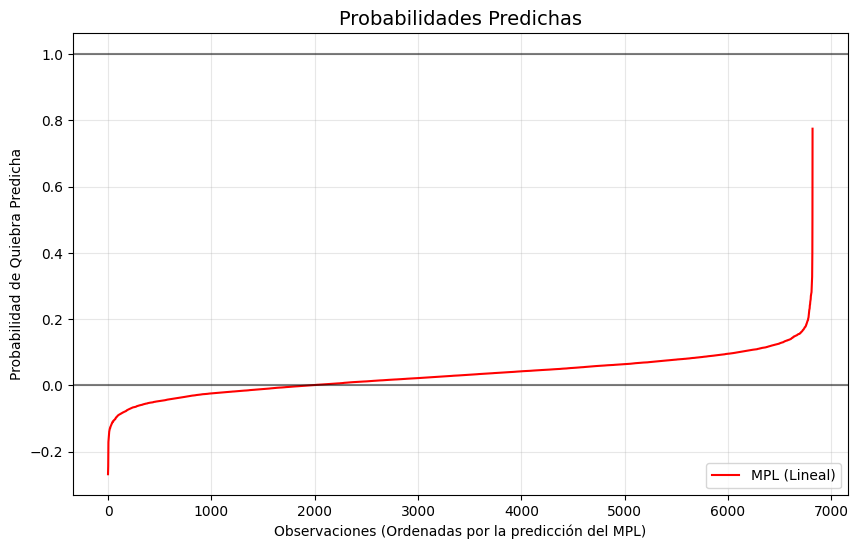

En la grafica se logra observar el problema de la probabilidad en un modelo MPL, donde aparecen valores negativos para 1942 empresas 


In [52]:
# Obtener las probabilidades predichas del MPL
pred_mpl = mpl_model.predict(df_2)
idx = np.argsort(pred_mpl)

# 2. Crear el gráfico comparativo
plt.figure(figsize=(10, 6))


plt.plot(np.sort(pred_mpl.to_numpy()), label='MPL (Lineal)', color='red')

# Líneas guía horizontales en 0 y 1
plt.axhline(0, color='black', linestyle='-', alpha=0.5)
plt.axhline(1, color='black', linestyle='-', alpha=0.5)

# Personalización del gráfico
plt.title('Probabilidades Predichas', fontsize=14)
plt.xlabel('Observaciones (Ordenadas por la predicción del MPL)')
plt.ylabel('Probabilidad de Quiebra Predicha')
plt.legend()
plt.grid(True, alpha=0.3)

# Mostrar gráfico
plt.show()

print (f"En la grafica se logra observar el problema de la probabilidad en un modelo MPL, donde aparecen valores negativos para 1942 empresas ")

## **Pregunta 5**

Estima un modelo logit y probit para predecir la probabilidad de quiebra de una empresa basado en sus ratios financieros.

$$P(bankruptcy=1∣roa,debt\_ratio,asset\_turnover)$$

¿Qué variables son estadísticamente significativas usando un nivel de significancia de 5%? ¿10%? ¿Tienen los coeficientes los signos esperados?

In [53]:
# 1. Definimos la fórmula del modelo según la imagen
formula = "bankruptcy ~ roa + debt_ratio + asset_turnover"

# --- MODELO LOGIT ---
logit_model = smf.logit(formula, data=df_2).fit()
print("\n=== RESUMEN MODELO LOGIT ===")
print(logit_model.summary())

# --- MODELO PROBIT ---
probit_model = smf.probit(formula, data=df_2).fit()
print("\n=== RESUMEN MODELO PROBIT ===")
print(probit_model.summary())

Optimization terminated successfully.
         Current function value: 0.095804
         Iterations 9

=== RESUMEN MODELO LOGIT ===
                           Logit Regression Results                           
Dep. Variable:             bankruptcy   No. Observations:                 6819
Model:                          Logit   Df Residuals:                     6815
Method:                           MLE   Df Model:                            3
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.3278
Time:                        19:17:11   Log-Likelihood:                -653.29
converged:                       True   LL-Null:                       -971.86
Covariance Type:            nonrobust   LLR p-value:                8.967e-138
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          1.1713      0.638      1.836      0.066      -0.079

R:

Todas las variables son estadisticamente significates para un nivel de significacion del 5% por ende para 10% tambien cumple.

Todos los signos son los esperados:

roa (−): más rentabilidad, menor probabilidad de quiebra.

debt_ratio (+): más apalancamiento, mayor probabilidad de quiebra.

asset_turnover (−): uso más eficiente de los activos, menor probabilidad de quiebra.


## **Pregunta 6**

¿En qué medida el incremento marginal en el nivel de apalancamiento (Debt ratio %) afecta la probabilidad de quiebra de las empresas? Calcula el APE y PEA para los modelos MPL, logit y probit. Compara los resultados.

In [54]:
# ==============================================================================
# CÁLCULO DE EFECTOS MARGINALES PARA DEBT_RATIO
# ==============================================================================

# Modelo MPL: El efecto marginal es constante e igual al coeficiente de la variable
efecto_mpl = mpl_model.params['debt_ratio']

# Modelo LOGIT
pea_logit_obj = logit_model.get_margeff(at='mean')
ape_logit_obj = logit_model.get_margeff(at='overall')

pea_logit = pea_logit_obj.margeff[1] # Índice 1 corresponde a 'debt_ratio'
ape_logit = ape_logit_obj.margeff[1]

# Modelo PROBIT
pea_probit_obj = probit_model.get_margeff(at='mean')
ape_probit_obj = probit_model.get_margeff(at='overall')

pea_probit = pea_probit_obj.margeff[1] # Índice 1 corresponde a 'debt_ratio'
ape_probit = ape_probit_obj.margeff[1]

# Imprimir la tabla comparativa estructurada
print("=== TABLA DE RESULTADOS: EFECTO MARGINAL DE DEBT_RATIO ===")
print(f"Modelo MPL    -> Efecto Único (APE y PEA): {efecto_mpl:.4f}")
print(f"Modelo LOGIT  -> PEA: {pea_logit:.4f} | APE: {ape_logit:.4f}")
print(f"Modelo PROBIT -> PEA: {pea_probit:.4f} | APE: {ape_probit:.4f}")

=== TABLA DE RESULTADOS: EFECTO MARGINAL DE DEBT_RATIO ===
Modelo MPL    -> Efecto Único (APE y PEA): 0.7237
Modelo LOGIT  -> PEA: 0.1890 | APE: 0.5421
Modelo PROBIT -> PEA: 0.1997 | APE: 0.4412


Un aumento de 0,01 en el debt ratio eleva la probabilidad de quiebra en 0,72 puntos porcentuales según el MPL, y en promedio (APE) en 0,54 pp en el logit y 0,44 pp en el probit. Para la empresa promedio (PEA), el efecto es menor: 0,19 pp en el logit y 0,20 pp en el probit. Esto ocurre porque su probabilidad predicha es baja (cercana a 0,8%), zona donde las curvas logística y normal son casi planas. El MPL impone un efecto constante para todas las empresas y lo sobrestima para la mayoría. Logit y probit muestran que el efecto del apalancamiento es mayor en las empresas más cercanas a la quiebra.

## **Pregunta 7**

Estás evaluando el riesgo de quiebra de una empresa cuyos ratios financieros normalizados toman los siguientes valores:

- ROA = 0

- Current Ratio = 0

- Total Asset Turnover = 0

Calcula la probabilidad predicha de quiebra del MPL, logit y probit, asumiendo los valores anteriores y que el ratio de deuda sea 0.1 y 0.2. Compara e interpreta los resultados obtenidos.

In [55]:
from IPython.display import display, Math
intercept = 0.2440
beta_debt_ratio = 0.7237
debt_ratio = 0.1
multiplicacion = beta_debt_ratio * debt_ratio
resultado_final = intercept + multiplicacion

debt_ratio2 = 0.2
multiplicacion2 = beta_debt_ratio * debt_ratio2
resultado_final2 = intercept + multiplicacion2

codigo_latex = rf"""
\hat{{P}} = \text{{Intercept}} + (\beta_{{\text{{debt\_ratio}}}}\times \text{{debt\_ratio}}) \\
\text{{para debt\_ratio}} = {debt_ratio}: \\
{intercept} + ({beta_debt_ratio} \times {debt_ratio}) = {intercept} + {multiplicacion:.4f} = \mathbf{{{resultado_final:.4f} \ (31.64\%)}}
"""
codigo_latex2 = rf"""
\hat{{P}} = \text{{Intercept}} + (\beta_{{\text{{debt\_ratio}}}}\times \text{{debt\_ratio2}}) \\
\text{{para debt\_ratio2}} = {debt_ratio2}: \\
{intercept} + ({beta_debt_ratio} \times {debt_ratio2}) = {intercept} + {multiplicacion2:.4f} = \mathbf{{{resultado_final2:.4f} \ (38.87\%)}}"""

print("========MODELO_PROBABILIDAD_LINEAL========")

display(Math(codigo_latex))
display(Math(codigo_latex2))

========MODELO_PROBABILIDAD_LINEAL========


<IPython.core.display.Math object>

<IPython.core.display.Math object>

 **======================MODELO LOGIT======================**

* **Fórmula:** $$Z = 1.1713 + (22.7619 \times \text{debt_ratio}) \rightarrow \hat{P} = \frac{1}{1 + e^{-Z}}$$

* **Para debt_ratio = 0.1:**
  * $$Z = 1.1713 + 2.2762 = 3.4475$$
  * $$\hat{P} = \frac{1}{1 + e^{-3.4475}} = \mathbf{0.9692 \ (96.92\%)}$$

* **Para debt_ratio = 0.2:**
  * $$Z = 1.1713 + 4.5524 = 5.7237$$
  * $$\hat{P} = \frac{1}{1 + e^{-5.7237}} = \mathbf{0.9967 \ (99.67\%)}$$


 **======================MODELO PROBIT======================**


 * **Fórmula:** $$Z = 0.8050 + (8.8199 \times \text{debt_ratio}) \rightarrow \hat{P} = \Phi(Z) (Donde \Phi$$ es la distribución normal acumulada)
* **Para debt_ratio = 0.1:**
	* $$Z = 0.8050 + 0.8820 = 1.6870$$
	* $$\hat{P} = \Phi(1.6870) = \mathbf{0.9542 \ (95.42\%)}$$
* **Para debt_ratio = 0.2:**
	* $$Z = 0.8050 + 1.7640 = 2.5690$$
	* $$\hat{P} = \Phi(2.5690) = \mathbf{0.9949 \ (99.49\%)}$$


ROA = 0 está unas 8 desviaciones estándar bajo la media (0,505 ± 0,061), así que es una extrapolación extrema.

El MPL, por ser lineal, subestima mucho el riesgo. Logit y probit capturan que la probabilidad se dispara y se acerca a 1.

Subir el debt ratio de 0,1 a 0,2 aumenta la probabilidad en 7,2 puntos en el MPL (efecto constante). En logit sube solo 2,8 puntos y en probit 4,1, porque la curva ya está en la zona donde se aplana.

## **Pregunta 8**

(a) Asigna aleatoriamente el 70% de las empresas a la muestra de entrenamiento y el 30% restante a la muestra de pruebam estratificando por `bankruptcy`. Usa una semilla igual a 1457. ¿Por qué es importante estratificar en este caso?

In [56]:
from sklearn.model_selection import train_test_split

# Split 70/30 estratificado por bankruptcy, semilla 1457
train, test = train_test_split(df_2,
                               test_size=0.3,
                               stratify=df_2['bankruptcy'],
                               random_state=1457)

# Verificación de tamaños y proporción de quiebras
print(f"Muestra de entrenamiento: {len(train)} empresas")
print(f"Muestra de prueba: {len(test)} empresas")
print(f"Proporción de quiebras (total):         {df_2['bankruptcy'].mean():.4f}")
print(f"Proporción de quiebras (entrenamiento): {train['bankruptcy'].mean():.4f}")
print(f"Proporción de quiebras (prueba):        {test['bankruptcy'].mean():.4f}")

Muestra de entrenamiento: 4773 empresas
Muestra de prueba: 2046 empresas
Proporción de quiebras (total):         0.0323
Proporción de quiebras (entrenamiento): 0.0323
Proporción de quiebras (prueba):        0.0323


Las clases están muy desbalanceadas (3,23%, solo 220 quiebras). Sin estratificar, la muestra de prueba (unas 66 quiebras esperadas) podría quedar por azar con muy pocas o demasiadas quiebras. Eso distorsionaría la estimación y métricas como el recall o el AUC. Estratificar garantiza la misma proporción en ambas muestras.

(b) Estima el modelo logit con los datos de la muestra de entrenamiento.

In [57]:
# 1. Añadir una constante (intercepto) a las variables explicativas
X_train = train[['roa', 'debt_ratio', 'asset_turnover']]
y_train = train['bankruptcy']
X_test  = test[['roa', 'debt_ratio', 'asset_turnover']]
y_test  = test['bankruptcy']

X_train_const = sm.add_constant(X_train)

# 2. Ajustar el modelo Logit
modelo_logit_sm = sm.Logit(y_train, X_train_const).fit()

# 3. Mostrar el resumen estadístico completo
print(modelo_logit_sm.summary())



Optimization terminated successfully.
         Current function value: 0.097647
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:             bankruptcy   No. Observations:                 4773
Model:                          Logit   Df Residuals:                     4769
Method:                           MLE   Df Model:                            3
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.3149
Time:                        19:17:11   Log-Likelihood:                -466.07
converged:                       True   LL-Null:                       -680.29
Covariance Type:            nonrobust   LLR p-value:                 1.526e-92
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.8851      0.763      2.471      0.013       0.390       3.381
roa              

## **Pregunta 9**

(a) Construye la matriz de confusión utilizando un cutoff del 50% con los datos de la muestra de prueba.

Matriz de Confusión:
 [[1974    6]
 [  55   11]]


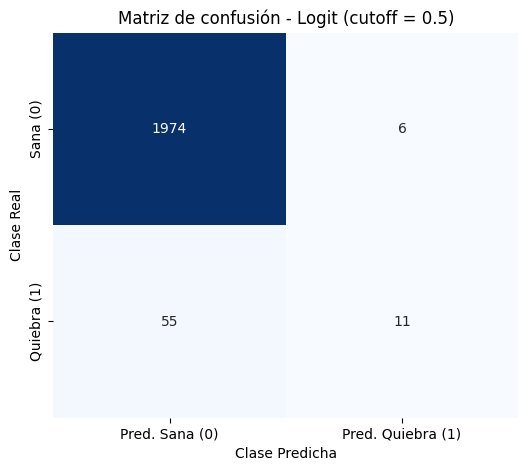

In [58]:
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. Obtener las probabilidades predichas para la muestra de prueba
X_test_const = sm.add_constant(X_test)
probabilidades = modelo_logit_sm.predict(X_test_const)

# 2. Aplicar el cutoff del 50% (0.5)
y_pred = (probabilidades >= 0.5).astype(int)

# 3. Calcular la matriz de confusión
matriz = confusion_matrix(y_test, y_pred)
print("Matriz de Confusión:\n", matriz)

# 4. Crear DataFrame para la visualización

cm_df = pd.DataFrame(matriz,
                     index=['Sana (0)', 'Quiebra (1)'],
                     columns=['Pred. Sana (0)', 'Pred. Quiebra (1)'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de confusión - Logit (cutoff = 0.5)')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

(b) Calcula las siguientes métricas: `accuracy`, `recall` y `especificidad`.

In [59]:
# Desempaquetar los valores de la matriz de confusión
# [[TN, FP],
#  [FN, VP]]
tn, fp, fn, vp = matriz.ravel()

# Calcular métricas
accuracy = (vp + tn) / (vp + tn + fp + fn)
recall = vp / (vp + fn)
especificidad = tn / (tn + fp)

# Mostrar resultados
print(f"Accuracy:       {accuracy:.4f}")
print(f"Recall (Sens.): {recall:.4f}")
print(f"Especificidad:  {especificidad:.4f}")


Accuracy:       0.9702
Recall (Sens.): 0.1667
Especificidad:  0.9970


## **Pregunta 10**

(a) Calcula la curva ROC y la métrica AUC. Interpreta el AUC.

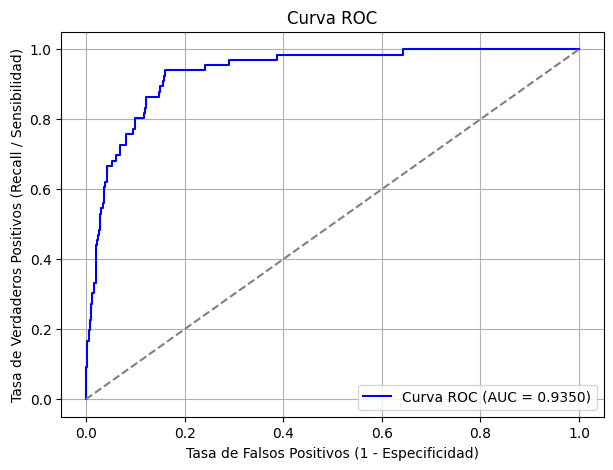

El valor del AUC es: 0.9350


In [60]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calcular las tasas de falsos positivos (FPR) y verdaderos positivos (TPR)
fpr, tpr, thresholds = roc_curve(y_test, probabilidades)

# 2. Calcular el Área Bajo la Curva (AUC)
auc_score = roc_auc_score(y_test, probabilidades)

# 3. Graficar la Curva ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='blue', label=f'Curva ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--') # Línea de clasificación aleatoria
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall / Sensibilidad)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"El valor del AUC es: {auc_score:.4f}")


(b) Un aumento del recall está asociado con una disminución de la tasa de falsos positivos. ¿Estás de acuerdo con esta afirmación? Justifica tu respuesta numéricamente.

In [61]:
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix

# 1. Asegurar el entrenamiento del modelo Logit en la muestra de entrenamiento
X_train_const = sm.add_constant(X_train)
modelo_logit_sm = sm.Logit(y_train, X_train_const).fit()

# 2. Calcular las probabilidades en la muestra de prueba
X_test_const = sm.add_constant(X_test)
probabilidades = modelo_logit_sm.predict(X_test_const)

# 3. Evaluar los diferentes cutoffs
cutoffs = [0.9, 0.7, 0.5, 0.3, 0.1, 0.05, 0.03, 0.01]
resultados = []

for c in cutoffs:
    y_pred_c = (probabilidades >= c).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_c).ravel()
    resultados.append({
        'Cutoff': c,
        'VP': tp, 'FN': fn, 'FP': fp, 'VN': tn,
        'Recall': tp / (tp + fn),
        'Tasa FP': fp / (fp + tn)
    })

tabla_cutoffs = pd.DataFrame(resultados)
tabla_cutoffs.round(4)

Optimization terminated successfully.
         Current function value: 0.097647
         Iterations 9


,Cutoff,VP,FN,FP,VN,Recall,Tasa FP
0,0.90,5,61,2,1978,0.0758,0.0010
1,0.70,10,56,4,1976,0.1515,0.0020
2,0.50,11,55,6,1974,0.1667,0.0030
3,0.30,14,52,15,1965,0.2121,0.0076
4,0.10,40,26,72,1908,0.6061,0.0364
5,0.05,53,13,203,1777,0.8030,0.1025
6,0.03,62,4,360,1620,0.9394,0.1818
7,0.01,65,1,865,1115,0.9848,0.4369


No, no estoy de acuerdo con esta afirmación. Ocurre exactamente lo contrario: un aumento del recall está asociado con un aumento de la tasa de falsos positivos (FPR).

Justificación numérica:

Existe un compromiso (trade-off) directo entre ambas métricas al modificar el umbral de decisión (cutoff):
*  **Definición de las métricas:**
$$\text{Recall (TPR)}=\frac{VP}{VP+FN}$$

$$\text{Tasa de Falsos Positivos (FPR)}=\frac{FP}{TN+FP}=1-\text{Especificidad}$$

* **Efecto de bajar el cutoff:**

Si disminuyes el cutoff (por ejemplo, del 50% al 20%) para asegurar capturar más empresas en quiebra:
* El modelo se vuelve más "sensible" y clasificará más casos como positivos (1).
* Esto incrementa los Verdaderos Positivos (\(VP\)), por lo que el Recall aumenta.
* Sin embargo, al clasificar más casos como positivos de forma agresiva, también cometerás más errores con las empresas sanas, aumentando los Falsos Positivos (\(FP\)). Al subir \(FP\), la Tasa de Falsos Positivos (FPR) también aumenta.

* **Evidencia visual en la curva ROC:**

Puedes observar matemáticamente este comportamiento en la gráfica del apartado
(a): la curva ROC siempre tiene pendiente positiva. Al moverte hacia arriba en el eje Y (mayor Recall), obligatoriamente te desplazas hacia la derecha en el eje X (mayor Tasa de Falsos Positivos).


## **Pregunta 11**

Si quieres disminuir la tasa de falsos positivos, debes disminuir el umbral $p_0$. ¿Estás de acuerdo con esta afirmación? Calcula la métrica relevante para justificar tu respuesta.

No, no estoy de acuerdo con esta afirmación. Para disminuir la tasa de falsos positivos (FPR), se debe aumentar el umbral p_{0} no disminuirlo.

Justificación teórica

* Al disminuir el umbral p_{0} (por ejemplo, de 0.5 a 0.2), el modelo se vuelve más permisivo para clasificar las observaciones como positivas (1). Esto hace que aumenten los Falsos Positivos (\(FP\)), lo que incrementa la tasa de falsos positivos.
* Al aumentar el umbral \(p_{0}\) (por ejemplo, de 0.5 a 0.8), el modelo es más exigente para diagnosticar un positivo. Esto reduce drásticamente la cantidad de Falsos Positivos (\(FP\)), logrando disminuir la tasa de falsos positivos.


In [62]:
from sklearn.metrics import confusion_matrix

def calcular_fpr(probabilidades, y_real, umbral):
    # Clasificar usando el umbral dado
    y_pred = (probabilidades >= umbral).astype(int)
    # Extraer componentes de la matriz de confusión
    tn, fp, fn, vp = confusion_matrix(y_real, y_pred).ravel()
    # Calcular Tasa de Falsos Positivos
    fpr = fp / (tn + fp)
    return fpr

# Calcular FPR para un umbral menor (disminuido) y uno mayor (aumentado)
fpr_umbral_bajo = calcular_fpr(probabilidades, y_test, umbral=0.20)
fpr_umbral_alto = calcular_fpr(probabilidades, y_test, umbral=0.80)

print(f"FPR con umbral disminuido (20%): {fpr_umbral_bajo:.4f}")
print(f"FPR con umbral aumentado (80%):  {fpr_umbral_alto:.4f}")
print("\nConclusión numérica: Al aumentar el umbral, el FPR disminuye.")


FPR con umbral disminuido (20%): 0.0177
FPR con umbral aumentado (80%):  0.0015

Conclusión numérica: Al aumentar el umbral, el FPR disminuye.
